# Predicting the Melting and Boiling Points of Hydrocarbons Using RDKit

## 1. Introduction

Hydrocarbons are chemical compounds made up of carbon and hydrogen. They are important components of fuels, solvents and many industrial products. Their physical properties, particularly melting point and boiling point, influence how they behave under different temperature conditions.

The aim of this project is to develop machine learning regression models that predict the melting and boiling points of hydrocarbons from their molecular structures. RDKit will be used to convert SMILES strings into molecular representations and calculate molecular descriptors.

The dataset contains 194 hydrocarbons from different structural classes. The initial models will use molecular weight and aromatic ring count as predictors.


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from rdkit import Chem
from rdkit.Chem import Descriptors, Draw

from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [110]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from rdkit import Chem
from rdkit.Chem import Descriptors, Draw

from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

In [111]:
# load the dataset
df = pd.read_csv("data/hydrocarbons.csv")
df.head(5)

,Class of hydrocarbon,IUPAC name,Melting point,Boiling point,Density,Flash point,Autoignition temp,pubchem_id,smiles
0,Trimetylalkane,"2,2,4-Trimethylpentane",-107.0,99.0,0.69,NaN,396,10907,CC(C)CC(C)(C)C
1,Triaromatics,Phenanthrene,99.0,338.0,1.18,171,>450,995,C1=CC=C2C(=C1)C=CC3=CC=CC=C32
2,Triaromatics,Anthracene,216.0,341.0,1.2825,NaN,NaN,8418,C1=CC=C2C=C3C=CC=CC3=CC2=C1
3,Triaromatics,1-methylanthracene,86.0,342.0,1.04799,NaN,NaN,11884,CC1=CC=CC2=CC3=CC=CC=C3C=C12
4,Triaromatics,2-methylanthracene,209.0,340.0,1.8,NaN,NaN,11936,CC1=CC2=CC3=CC=CC=C3C=C2C=C1


## Inspecting the Dataset

Before calculating molecular descriptors, I will inspect the dataset to understand its structure. I will check how many rows and columns it contains, review the column names, and count missing values in each column. This will help me identify any data quality issues that need to be handled.

In [112]:
# Show the number of rows and columns in the dataset
print("Dataset shape:", df.shape)

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing values"))

Dataset shape: (194, 9)
Column names:
['Class of hydrocarbon', 'IUPAC name', 'Melting point', 'Boiling point', 'Density', 'Flash point', 'Autoignition temp', 'pubchem_id', 'smiles']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 194 entries, 0 to 193
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Class of hydrocarbon  194 non-null    str    
 1   IUPAC name            194 non-null    str    
 2   Melting point         188 non-null    float64
 3   Boiling point         190 non-null    float64
 4   Density               189 non-null    str    
 5   Flash point           77 non-null     str    
 6   Autoignition temp     63 non-null     str    
 7   pubchem_id            194 non-null    int64  
 8   smiles                194 non-null    str    
dtypes: float64(2), int64(1), str(6)
memory usage: 13.8 KB

Missing values:


,Missing values
Class of hydrocarbon,0
IUPAC name,0
Melting point,6
Boiling point,4
Density,5
Flash point,117
Autoignition temp,131
pubchem_id,0
smiles,0


## Checking SMILES Validity

SMILES strings describe the structures of molecules. I will use RDKit to convert each SMILES string into a molecule object. I will then check whether any strings fail to parse.

All valid molecules will be used for descriptor calculations. If any SMILES strings are invalid, I will inspect them before deciding how to handle those rows.

In [113]:
df["mol"] = df["smiles"].apply(Chem.MolFromSmiles)

invalid_smiles = df["mol"].isnull()

print("Total molecules:", len(df))
print("Invalid SMILES:", invalid_smiles.sum())

if invalid_smiles.any():
    display(df.loc[invalid_smiles, ["IUPAC name", "smiles"]])

Total molecules: 194
Invalid SMILES: 0


## Data validation

The dataset was loaded using pandas, and its dimensions, column names, data types and missing values were inspected. Each SMILES string was then converted into an RDKit molecule object.

Valid molecular representations are necessary for calculating descriptors. Any SMILES strings that fail to parse must be investigated before proceeding.

Missing melting and boiling point values will be handled separately for each modelling task. A molecule without a measured boiling point can still be used in melting point modelling if its melting point is available, and vice versa.

In [114]:
df["canonical_smiles"] = df["mol"].apply(
    lambda mol: Chem.MolToSmiles(mol, canonical=True)
    if mol is not None else np.nan
)

df["Molecular weight"] = df["mol"].apply(
    lambda mol: Descriptors.MolWt(mol)
    if mol is not None else np.nan
)

df["Aromatic ring count"] = df["mol"].apply(
    lambda mol: Descriptors.NumAromaticRings(mol)
    if mol is not None else np.nan
)

display(
    df[[
        "IUPAC name",
        "smiles",
        "Molecular weight",
        "Aromatic ring count",
        "Melting point",
        "Boiling point"
    ]].head(10)
)

,IUPAC name,smiles,Molecular weight,Aromatic ring count,Melting point,Boiling point
0,"2,2,4-Trimethylpentane",CC(C)CC(C)(C)C,114.232,0,-107.0,99.0
1,Phenanthrene,C1=CC=C2C(=C1)C=CC3=CC=CC=C32,178.234,3,99.0,338.0
2,Anthracene,C1=CC=C2C=C3C=CC=CC3=CC2=C1,178.234,3,216.0,341.0
3,1-methylanthracene,CC1=CC=CC2=CC3=CC=CC=C3C=C12,192.261,3,86.0,342.0
4,2-methylanthracene,CC1=CC2=CC3=CC=CC=C3C=C2C=C1,192.261,3,209.0,340.0
5,"1,2,3,4-tetrahydro-naphthalene",C1CCC2=CC=CC=C2C1,132.206,1,-35.0,207.0
6,"1,2,3,4-tetrahydro-5-methyl-naphthalene",CC1=C2CCCCC2=CC=C1,146.233,1,-23.0,234.0
7,Benzophenanthrene,C1=CC=C2C(=C1)C3=CC=CC=C3C4=CC=CC=C24,228.294,4,256.0,448.0
8,Chrysene,C1=CC=C2C(=C1)C=CC3=C2C=CC4=CC=CC=C43,228.294,4,255.0,448.0
9,Triphenylene,C1=CC=C2C(=C1)C3=CC=CC=C3C4=CC=CC=C24,228.294,4,196.0,438.0


In [115]:
# check molecule duplicates based on canonical SMILES
duplicate_mask = df["canonical_smiles"].duplicated(keep=False)

duplicates = df.loc[
    duplicate_mask,
    [
        "IUPAC name",
        "Class of hydrocarbon",
        "canonical_smiles",
        "Melting point",
        "Boiling point"
    ]
].sort_values("canonical_smiles")

print("Number of rows involved in duplicate groups:", duplicate_mask.sum())
print(
    "Number of repeated canonical SMILES after the first occurrence:",
    df["canonical_smiles"].duplicated().sum()
)

display(duplicates)

Number of rows involved in duplicate groups: 4
Number of repeated canonical SMILES after the first occurrence: 2


,IUPAC name,Class of hydrocarbon,canonical_smiles,Melting point,Boiling point
48,trans-Decahydronaphthalene,Dicycloalkane,C1CCC2CCCCC2C1,-30.0,187.0
49,cis-Decahydronaphthalene,Dicycloalkane,C1CCC2CCCCC2C1,-43.0,196.0
7,Benzophenanthrene,Tetraaromatics,c1ccc2c(c1)c1ccccc1c1ccccc21,256.0,448.0
9,Triphenylene,Tetraaromatics,c1ccc2c(c1)c1ccccc1c1ccccc21,196.0,438.0


##  Duplicate molecular representations

Canonical SMILES provide a standardised representation that can help identify molecules with equivalent encoded structures. The canonical SMILES strings were compared to identify repeated representations.

Repeated canonical SMILES require investigation because they can represent duplicate records, missing stereochemical information, or inconsistencies between molecular names and structures.

The original records will be retained for the initial analysis rather than automatically deleting potentially distinct isomers. However, the modelling split will keep records with the same canonical SMILES in the same partition. This reduces the risk of placing identical molecular representations in both the training and test sets.

Canonical SMILES cannot identify distinctions that were never encoded in the original SMILES. Consequently, any structural ambiguity must be acknowledged when interpreting the results.

In [116]:
features = [
    "Molecular weight",
    "Aromatic ring count"
]

targets = ["Boiling point", "Melting point"]

model_df = df.dropna(
    subset=features + ["canonical_smiles"]
).copy()

print("Rows available before target-specific filtering:", len(model_df))
print("\nAvailable target measurements:")
print(model_df[targets].notna().sum())

print("\nMissing target measurements:")
print(model_df[targets].isna().sum())

Rows available before target-specific filtering: 194

Available target measurements:
Boiling point    190
Melting point    188
dtype: int64

Missing target measurements:
Boiling point    4
Melting point    6
dtype: int64


##  Exploratory data analysis

Exploratory data analysis will be used to investigate how molecular weight and aromatic ring count relate to boiling point and melting point.

Molecular weight may help explain differences in boiling point because molecular size and intermolecular dispersion forces influence the energy required for molecules to enter the gas phase. Aromatic ring count may provide additional information about molecular structure.

Melting point may be harder to explain using these two descriptors alone. Melting depends not only on molecular size but also on molecular symmetry, shape and how efficiently molecules pack into a crystal.

Scatter plots will be used to examine these relationships before fitting the regression models.

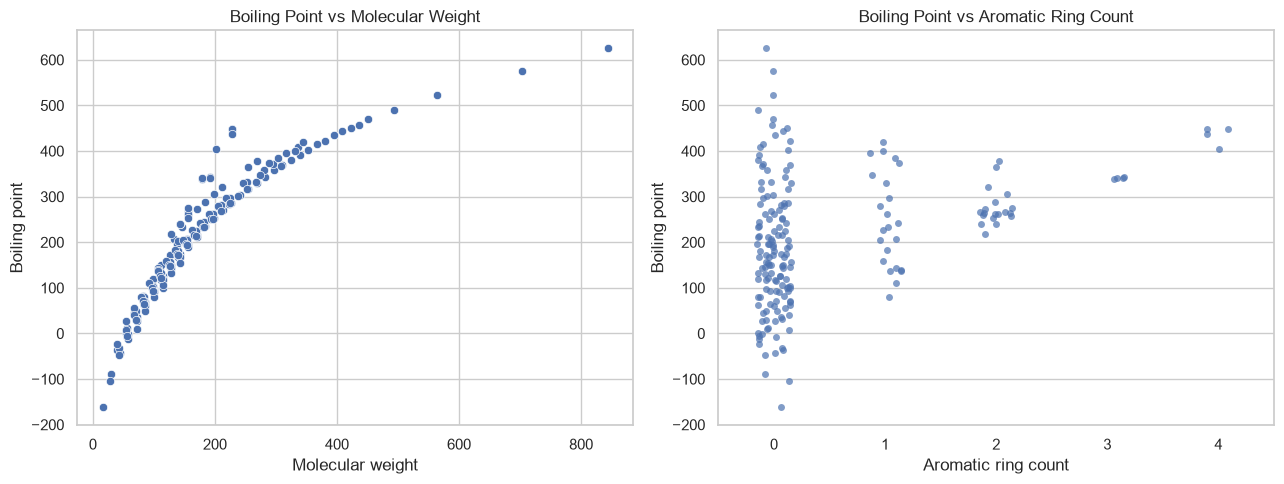

In [117]:
boiling_data = model_df.dropna(subset=["Boiling point"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(
    data=boiling_data,
    x="Molecular weight",
    y="Boiling point",
    ax=axes[0]
)
axes[0].set_title("Boiling Point vs Molecular Weight")

sns.stripplot(
    data=boiling_data,
    x="Aromatic ring count",
    y="Boiling point",
    jitter=0.15,
    alpha=0.7,
    ax=axes[1]
)
axes[1].set_title("Boiling Point vs Aromatic Ring Count")

plt.tight_layout()
plt.show()

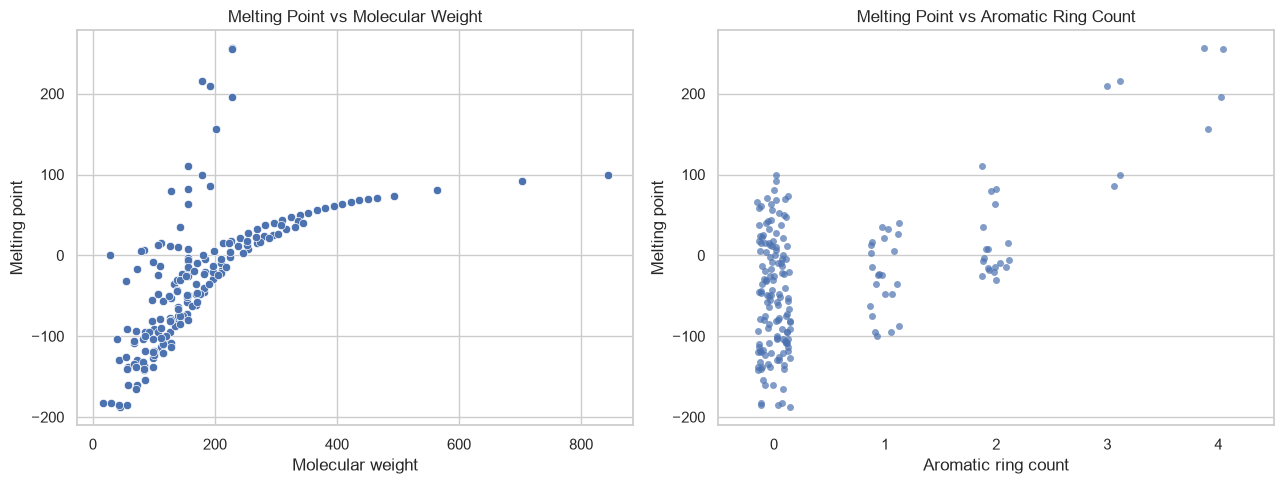

In [118]:
melting_data = model_df.dropna(subset=["Melting point"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(
    data=melting_data,
    x="Molecular weight",
    y="Melting point",
    ax=axes[0]
)
axes[0].set_title("Melting Point vs Molecular Weight")

sns.stripplot(
    data=melting_data,
    x="Aromatic ring count",
    y="Melting point",
    jitter=0.15,
    alpha=0.7,
    ax=axes[1]
)
axes[1].set_title("Melting Point vs Aromatic Ring Count")

plt.tight_layout()
plt.show()

## Interpreting the exploratory plots

The scatter plots show how the two molecular descriptors relate to the target properties. The strength and consistency of these relationships should be assessed from the plotted observations rather than assumed in advance.

For boiling point, I will examine whether higher molecular weight is generally associated with higher boiling point and whether aromatic ring count provides a visible separation between groups of molecules.

For melting point, I will examine the spread of values among molecules with similar molecular weights and aromatic ring counts. A large spread would suggest that the two descriptors do not capture all the structural factors affecting melting behaviour.

The plots provide an initial understanding of the data, but predictive performance must be evaluated using observations that were not used to train the models.

## Handling missing measurements

The dataset contains missing values in both target columns. Missing density, flash point and autoignition temperature values are not relevant to this modelling task because these measurements will not be used as predictors.

For boiling point modelling, rows without a measured boiling point will be excluded. For melting point modelling, rows without a measured melting point will be excluded.

The missing target values will not be replaced with estimated values because doing so would introduce artificial labels into the training data. Each model will therefore use the available observations for its respective target.

In [119]:
def evaluate_models(data, target, features):
    data = data.dropna(
        subset=features + [target, "canonical_smiles"]
    ).copy()

    X = data[features]
    y = data[target]
    groups = data["canonical_smiles"]

    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.2,
        random_state=42
    )

    train_idx, test_idx = next(
        splitter.split(X, y, groups=groups)
    )

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]
    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    models = {
        "Linear Regression": LinearRegression(),
        "Random Forest": RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            min_samples_leaf=2
        )
    }

    results = []
    predictions = {}

    for name, model in models.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        r2 = r2_score(y_test, y_pred)

        results.append({
            "Target": target,
            "Model": name,
            "Test samples": len(y_test),
            "RMSE": rmse,
            "R²": r2
        })

        predictions[name] = y_pred

        plt.figure(figsize=(6, 5))
        plt.scatter(y_test, y_pred, alpha=0.75)

        lower = min(y_test.min(), y_pred.min())
        upper = max(y_test.max(), y_pred.max())

        plt.plot(
            [lower, upper],
            [lower, upper],
            linestyle="--"
        )

        plt.xlabel("Actual values (°C)")
        plt.ylabel("Predicted values (°C)")
        plt.title(f"{target}: {name}")
        plt.tight_layout()
        plt.show()

    results_df = pd.DataFrame(results)
    return results_df

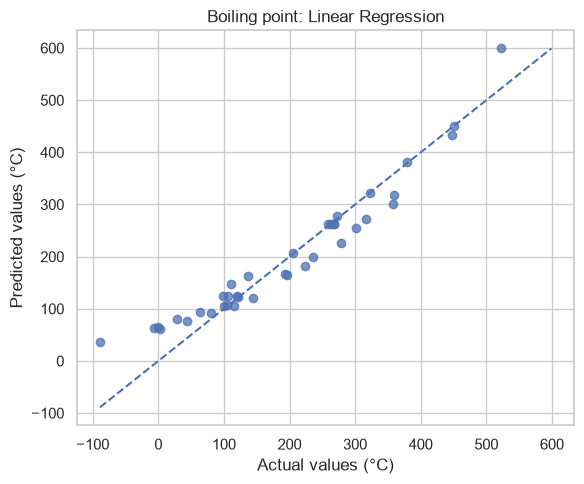

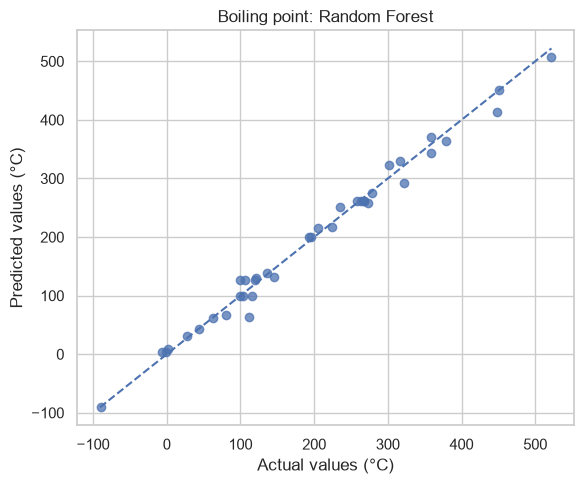

,Target,Model,Test samples,RMSE,R²
1,Boiling point,Random Forest,38,15.196451,0.988200
0,Boiling point,Linear Regression,38,39.637692,0.919716


In [120]:
boiling_results = evaluate_models(
    data=model_df,
    target="Boiling point",
    features=features
)

display(
    boiling_results.sort_values("RMSE")
)

## Boiling Point Prediction Results

Two regression models, Linear Regression and Random Forest, were trained to predict the boiling points of hydrocarbons using molecular weight and aromatic ring count.

Random Forest achieved an RMSE of 15.20°C and an R² of 0.9882 on the test set of 38 molecules. Linear Regression achieved an RMSE of 39.64°C and an R² of 0.9197 on the same number of test observations.

Random Forest performed better according to both evaluation metrics, producing lower prediction errors and a higher R². This suggests that it captured relationships in the data that the linear model did not represent as effectively.

Both models achieved positive R² values, indicating better performance than a baseline that predicts the mean boiling point of the test observations. However, the results apply to this particular test split and should not be interpreted as proof of equivalent performance on all unseen hydrocarbons.

The results suggest that molecular weight and aromatic ring count provide useful information for predicting boiling point, although further validation would be needed to establish how reliably the model generalises.

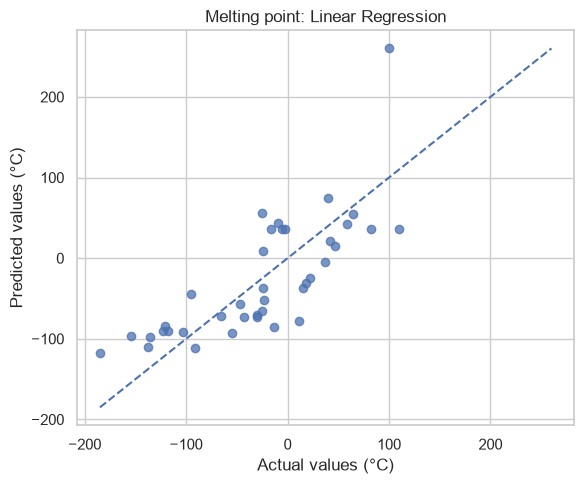

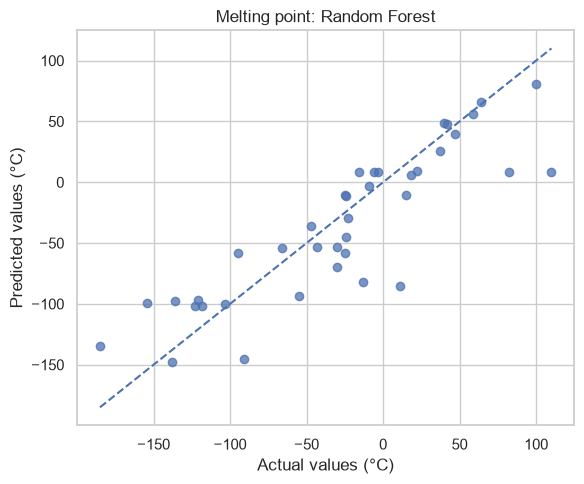

,Target,Model,Test samples,RMSE,R²
1,Melting point,Random Forest,39,36.108855,0.745386
0,Melting point,Linear Regression,39,50.572933,0.500552


In [121]:
melting_results = evaluate_models(
    data=model_df,
    target="Melting point",
    features=features
)

display(
    melting_results.sort_values("RMSE")
)

##  Melting Point Prediction Results

The same two regression algorithms were evaluated for melting point prediction, using molecules with available melting point measurements.

Random Forest achieved an RMSE of 36.11°C and an R² of 0.7454 on 39 test observations. Linear Regression achieved an RMSE of 50.57°C and an R² of 0.5006.

Random Forest performed better than Linear Regression according to both metrics. However, the errors were considerably larger than those observed for boiling point prediction, and the R² was lower.

These results suggest that molecular weight and aromatic ring count capture some of the variation in melting point but do not fully represent the structural factors that determine it.

Molecular symmetry, molecular shape and crystal packing can influence melting behaviour. Since the current models do not explicitly represent these properties, their predictions may be less accurate for molecules with different solid-state packing characteristics.

The results are based on a single test split, so additional validation would be useful before drawing broader conclusions.

In [122]:
all_results = pd.concat(
    [boiling_results, melting_results],
    ignore_index=True
)

display(
    all_results.sort_values(
        ["Target", "RMSE"]
    )
)

,Target,Model,Test samples,RMSE,R²
1,Boiling point,Random Forest,38,15.196451,0.988200
0,Boiling point,Linear Regression,38,39.637692,0.919716
3,Melting point,Random Forest,39,36.108855,0.745386
2,Melting point,Linear Regression,39,50.572933,0.500552


##  Comparing Boiling Point and Melting Point Prediction

The results indicate that boiling point was easier to predict than melting point using the selected molecular descriptors.

Random Forest achieved an RMSE of 15.20°C and an R² of 0.9882 for boiling point, compared with an RMSE of 36.11°C and an R² of 0.7454 for melting point. The boiling point model therefore had smaller absolute prediction errors and explained a larger proportion of the variation in the test observations.

A possible physical explanation is that boiling point is influenced by molecular size and intermolecular dispersion forces. Molecular weight provides a useful, although incomplete, indication of molecular size, while aromatic ring count contributes information about molecular structure.

Melting point depends on additional factors associated with the solid state. Molecular symmetry, shape and crystal packing influence how molecules arrange themselves in a crystal lattice. Molecules with identical molecular weights and aromatic ring counts can therefore have substantially different melting points.

These results illustrate that descriptors which are useful for predicting one physical property may be insufficient for another. Additional structural descriptors and more robust validation could help determine whether the observed difference in predictability persists across different samples of hydrocarbons.

,IUPAC name,Molecular weight,Aromatic ring count,Melting point,Boiling point
78,Cyclohexane,84.162,0,7.0,81.0
83,Methylcyclopentane,84.162,0,-142.0,72.0


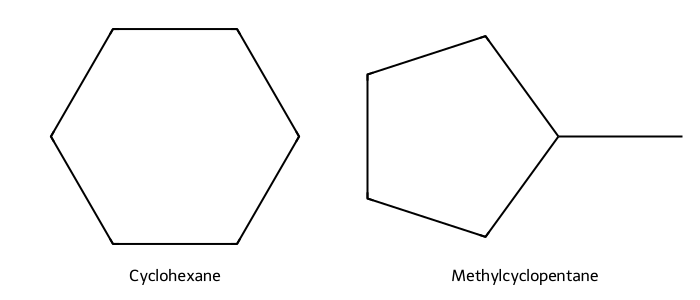

In [123]:
# find molecules with idenytical descriptors
pair_names = ["Cyclohexane", "Methylcyclopentane"]

pair_df = df[df["IUPAC name"].isin(pair_names)].copy()

display(
    pair_df[[
        "IUPAC name",
        "Molecular weight",
        "Aromatic ring count",
        "Melting point",
        "Boiling point"
    ]]
)

molecules = pair_df["mol"].tolist()
legends = pair_df["IUPAC name"].tolist()

display(
    Draw.MolsToGridImage(
        molecules,
        molsPerRow=2,
        subImgSize=(350, 300),
        legends=legends
    )
)

##  Molecular Structure and Melting Point

The analysis identified several groups of hydrocarbons with identical molecular weight and aromatic ring count but different melting points.

One example is cyclohexane and methylcyclopentane. Both have a molecular weight of 84.162 g/mol and zero aromatic rings, yet their melting points are 7°C and −142°C, respectively. This represents a difference of 149°C.

Another example is n-pentane, 2-methylbutane and 2,2-dimethylpropane. These molecules have the same molecular formula and molecular weight, but their melting points differ substantially. This demonstrates that branching and molecular symmetry can influence melting behaviour even when molecular weight remains constant.

The results illustrate a limitation of using only molecular weight and aromatic ring count. These descriptors do not fully capture molecular shape, branching, symmetry or crystal packing.

When different molecules have identical predictor values but different measured melting points, a model using these descriptors cannot distinguish between them. This limits the accuracy that can be achieved without additional structural information.

RDKit molecular drawings help visualise these structural differences and support the explanation of why melting point is more difficult to predict than boiling point using the initial descriptors.

In [124]:
#Investigating other descriptors collisions 
melting_pairs = (
    df.dropna(subset=["Melting point"])
    .groupby(features)
    .agg(
        Number_of_molecules=("IUPAC name", "size"),
        Melting_point_range=(
            "Melting point",
            lambda x: x.max() - x.min()
        ),
        Molecules=(
            "IUPAC name",
            lambda x: ", ".join(x)
        )
    )
    .reset_index()
)

melting_pairs = melting_pairs[
    melting_pairs["Number_of_molecules"] > 1
].sort_values(
    "Melting_point_range",
    ascending=False
)

display(melting_pairs.head(10))

,Molecular weight,Aromatic ring count,Number_of_molecules,Melting_point_range,Molecules
20,84.162,0,2,149.0,"Cyclohexane, Methylcyclopentane"
15,72.151,0,3,143.0,"N-pentane, 2-methylbutane, 2,2-dimethylpropane"
35,112.216,0,3,132.0,"Cyclooctane, propylcyclopentane, Ethylcyclohexane"
27,98.189,0,3,130.0,"Cycloheptane, Ethylcyclopentane, Methylcyclohe..."
58,156.228,2,8,126.0,"1-ethylnaphthalene, 2-ethylnaphthalene, 1,3-di..."
76,192.261,3,2,123.0,"1-methylanthracene, 2-methylanthracene"
41,126.243,0,2,106.0,"Cyclononane, Propylcyclohexane"
8,56.108,0,2,94.0,"Cyclobutane, But-1-ene"
49,140.270,0,2,74.0,"Cyclodecane, 2-methyl-1-nonene"
14,70.135,0,2,71.0,"Cyclopentane, 1-pentene"


In [125]:
df["Total ring count"] = df["mol"].apply(
    lambda mol: Descriptors.RingCount(mol)
    if mol is not None else np.nan
)

df["Rotatable bond count"] = df["mol"].apply(
    lambda mol: Descriptors.NumRotatableBonds(mol)
    if mol is not None else np.nan
)

df["Fraction Csp3"] = df["mol"].apply(
    lambda mol: Descriptors.FractionCSP3(mol)
    if mol is not None else np.nan
)

extended_features = [
    "Molecular weight",
    "Aromatic ring count",
    "Total ring count",
    "Rotatable bond count",
    "Fraction Csp3"
]

display(
    df[["IUPAC name"] + extended_features].head(10)
)

,IUPAC name,Molecular weight,Aromatic ring count,Total ring count,Rotatable bond count,Fraction Csp3
0,"2,2,4-Trimethylpentane",114.232,0,0,1,1.000000
1,Phenanthrene,178.234,3,3,0,0.000000
2,Anthracene,178.234,3,3,0,0.000000
3,1-methylanthracene,192.261,3,3,0,0.066667
4,2-methylanthracene,192.261,3,3,0,0.066667
5,"1,2,3,4-tetrahydro-naphthalene",132.206,1,2,0,0.400000
6,"1,2,3,4-tetrahydro-5-methyl-naphthalene",146.233,1,2,0,0.454545
7,Benzophenanthrene,228.294,4,4,0,0.000000
8,Chrysene,228.294,4,4,0,0.000000
9,Triphenylene,228.294,4,4,0,0.000000


In [126]:
def compare_features(data, target):
    # Filter data
    sub_features = ["Molecular weight", "Aromatic ring count", "Total ring count", "Rotatable bond count", "Fraction Csp3"]
    df_clean = data.dropna(subset=sub_features + [target, "canonical_smiles"]).copy()
    
    X_base = df_clean[["Molecular weight", "Aromatic ring count"]]
    X_ext = df_clean[sub_features]
    y = df_clean[target]
    groups = df_clean["canonical_smiles"]
    
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
    train_idx, test_idx = next(splitter.split(X_base, y, groups=groups))
    
    results = []
    
    feature_sets = {
        "Baseline (2 features)": X_base,
        "Extended (5 features)": X_ext
    }
    
    models = {
        "Linear Regression": LinearRegression(),
        "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, min_samples_leaf=2)
    }
    
    for f_name, X_data in feature_sets.items():
        X_train, X_test = X_data.iloc[train_idx], X_data.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        
        for m_name, model in models.items():
            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)
            
            rmse = np.sqrt(mean_squared_error(y_test, y_pred))
            r2 = r2_score(y_test, y_pred)
            
            results.append({
                "Target": target,
                "Features": f_name,
                "Model": m_name,
                "RMSE": rmse,
                "R²": r2
            })
            
    return pd.DataFrame(results)



In [127]:
extension_results = pd.concat(
    [
        compare_features(df, "Boiling point"),
        compare_features(df, "Melting point")
    ],
    ignore_index=True
)

display(extension_results)

,Target,Features,Model,RMSE,R²
0,Boiling point,Baseline (2 features),Linear Regression,39.637692,0.919716
1,Boiling point,Baseline (2 features),Random Forest,15.196451,0.988200
2,Boiling point,Extended (5 features),Linear Regression,38.874180,0.922779
3,Boiling point,Extended (5 features),Random Forest,13.763624,0.990320
4,Melting point,Baseline (2 features),Linear Regression,50.572933,0.500552
5,Melting point,Baseline (2 features),Random Forest,36.108855,0.745386
6,Melting point,Extended (5 features),Linear Regression,49.449304,0.522498
7,Melting point,Extended (5 features),Random Forest,31.739129,0.803282
